# 08 Klasifikasi Semi-Supervised

Label sedikit, data tanpa label banyak. **Cara pakai: ubah sel Config, lalu Run All.**

1. Kartu Masalah
2. Kapan Pakai
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Klasifikasi teks dengan sedikit label dan banyak data tanpa label |
| **Unit prediksi** | Satu teks mendapat satu kelas |
| **Metrik** | Sesuai soal, diatur di `METRIC` |
| **Masalah terbesar** | Dideteksi otomatis di bagian 4, baris `MASALAH TERBESAR` |

## 2. Kapan Pakai

**Pakai kalau** soal memberi data berlabel dan tanpa label, atau semuanya berlabel. Notebook yang sama juga jalan
untuk biner dan multi-kelas.

| Kondisi data | Yang terjadi |
|---|---|
| Sebagian label kosong | Baris kosong menjadi data tanpa label, dan self-training dicoba |
| Semua berlabel | Self-training dilewati |
| Jumlah kelas berapa pun | Dibaca dari data |
| Label test ada atau tidak | Kolom skor test muncul hanya kalau labelnya ada |
| Test bergeser dari data latih | Skor OOF diberi bobot mirip test, dan pengali kelas dimatikan |
| Waktu mepet | Student dan model tambahan dilewati otomatis |
| Pretrained dilarang atau file model tidak ada | Otomatis memakai TF-IDF |

**Copot pasang:** tiap langkah di bawah adalah satu sel yang berdiri sendiri. Kodenya ada di folder `nlp_kit`.

## 3. Config

Hanya sel ini yang perlu diubah. `TEXT_COL` boleh berupa daftar kolom, misalnya `["judul", "isi"]`.

In [1]:
TRAIN_PATH = "data/train.csv"
TEST_PATH = "data/test.csv"
TEXT_COL = "text"
LABEL_COL = "label"
ID_COL = None  # nama kolom id di test, None kalau tidak ada
GROUP_COL = None  # kolom yang tidak boleh lintas fold, misalnya id video
POSITIVE_CLASS = None  # hanya untuk METRIC "f1"
METRIC = "macro_f1"  # macro_f1, f1, weighted_f1, atau accuracy
WAKTU_MENIT = 60  # jumlah fold, epoch, dan model menyesuaikan batas ini
MODEL_DIR = "../../offline/models"
MODELS = ["indobertweet", "indobert"]  # kosongkan untuk hanya memakai TF-IDF
PAKAI_TEST_SAAT_LATIH = False  # True hanya kalau aturan lomba membolehkan
SEED = 42

Muat `nlp_kit` dan mulai pengatur waktu. Mode offline sudah aktif dari sini.

In [2]:
import sys

sys.path.insert(0, "../..")
import nlp_kit as nk

clock = nk.start(WAKTU_MENIT, SEED)

device=cuda | batas waktu=60 menit | seed=42


## 4. EDA

Muat data. Format csv, tsv, xlsx, json, jsonl, dan parquet dikenali otomatis.

In [3]:
data = nk.load_task(TRAIN_PATH, TEST_PATH, TEXT_COL, LABEL_COL, ID_COL, GROUP_COL, POSITIVE_CLASS)
data.labeled.head(3)

berlabel=500 | tanpa_label=4500 | test=500 | kelas=['negative', 'neutral', 'positive'] | label_test=ada


,text,label,audit
0,restoran ini terletak di jalan braga bandung . cukup ramai dan macet setiap hari nya . menu makanan yang d...,positive,positive
1,sby berkuasa tanya habib rizieq amp ; fery juliantono yang pernah terbuai jaman nya prabowo berkuasa tanya...,positive,positive
2,"terima kasih banyak noona , aku puas banget sama post it dan signed pagi nya ? noona begitu baik dan ramah...",positive,positive


Rencana pelatihan dari batas waktu dan jumlah label.

In [4]:
plan = nk.plan_training(WAKTU_MENIT, len(data.labeled))

Plan(folds=5, epochs=10, student_epochs=4, rounds=2)


Grafik, lalu masalah terbesar yang terdeteksi dari data ini.

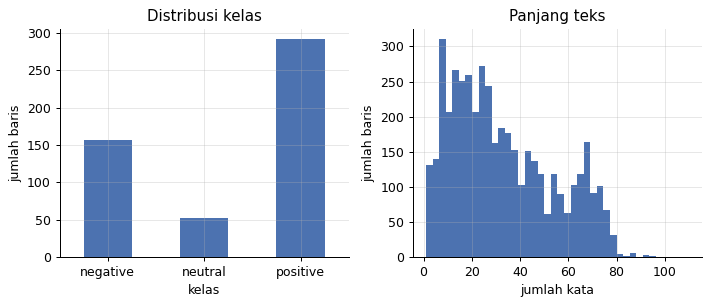

MASALAH TERBESAR: Test bergeser dari data latih, AUC adversarial 0.831


,berlabel,test,tanpa_label
baris,500.00,500.0,4500.0
duplikat_%,0.00,0.0,0.2
kata_median,29.00,22.0,28.0
kata_p95,71.05,52.0,71.0
kata_maks,92.00,90.0,110.0
url_%,0.00,0.0,0.0
emoji_%,0.00,0.0,0.0
html_%,0.00,0.0,0.0
byte_emoji_%,0.00,0.0,0.0


In [5]:
profile = nk.eda_report(data, plan.folds)
profile.table

**Temuan dan keputusan.** Tabel ini dihasilkan dari data, jadi berubah mengikuti data lu. Langkah berikutnya memakai
keputusan ini.

In [6]:
profile.findings

,temuan,keputusan
0,"Test bergeser dari data latih, AUC adversarial 0.831","Skor OOF diberi bobot mirip test, dan pengali kelas dimatikan"
1,Label hanya 500 baris,"Selisih skor kecil dianggap noise, model baru dipakai kalau peluangnya lebih baik minimal 0,9"
2,Kelas timpang: neutral 10.4%,"Pakai bobot kelas, dan kuota pseudo-label per kelas"
3,Ada 4500 baris tanpa label,"Self-training dicoba, dipakai hanya kalau terbukti naik"
4,Duplikat persis 0.0%,Grup near-duplicate tidak boleh lintas fold
5,95% teks di bawah 71 kata,Panjang token model 128


## 5. Preprocessing

Hanya membuang gangguan teknis: URL, mention, HTML, dan token anonimisasi. Stopword, emoji, dan slang tetap, karena
transformer butuh teks utuh. Grup near-duplicate dihitung supaya teks kembar tidak bocor antar fold.

In [7]:
nk.preprocess(data)

grup validasi: 500 dari 500 baris


## 6. Validasi

Metrik diuji dulu pada contoh yang jawabannya sudah dihitung manual, lalu fold dibuat. Tiap fold melatih teacher dan
student hanya dari fold latih, supaya label validasi tidak bocor lewat pseudo-label.

In [8]:
nk.check_metrics()
folds = nk.make_folds(data, plan.folds, SEED)
board = nk.Leaderboard(data, METRIC, SEED)

metrik lolos uji
baris per fold: [101, 100, 100, 99, 100]


## 7. Baseline

Tebak mayoritas dan TF-IDF + regresi logistik. TF-IDF juga menjadi cadangan kalau waktu habis atau pretrained dilarang.

In [9]:
baseline = nk.run_baseline(data, folds, board, PAKAI_TEST_SAAT_LATIH)

{'model': 'mayoritas', 'oof': 0.2453, 'oof_ci95': '0.234-0.256', 'oof_mirip_test': 0.2059, 'test': 0.1959}


[waktu] baseline_tfidf: 8 detik


{'model': 'tfidf_lr', 'oof': 0.6652, 'oof_ci95': '0.603-0.720', 'oof_mirip_test': 0.6484, 'test': 0.5322}


## 8. Model Utama

**Self-training dengan kuota per kelas.** Teacher dilatih dari data berlabel, memprediksi data tanpa label, lalu baris
paling yakin di tiap kelas dijadikan pseudo-label untuk melatih student.

In [10]:
models = nk.run_self_training(
    data, folds, board, plan, MODELS, MODEL_DIR, profile, PAKAI_TEST_SAAT_LATIH
)

indobertweet seed 42: 901 detik


indobert seed 42: 919 detik


indobertweet seed 43: 895 detik
sisa waktu tidak cukup, 1 model tambahan dilewati
[waktu] model_utama: 2714 detik


{'model': 'transformer_teacher', 'oof': 0.8611, 'oof_ci95': '0.819-0.899', 'oof_mirip_test': 0.8668, 'test': 0.8069}


{'model': 'transformer_student', 'oof': 0.8741, 'oof_ci95': '0.835-0.912', 'oof_mirip_test': 0.8845, 'test': 0.8156}
model selesai: 3 dari 4


## 9. Post-processing

Model lebih rumit dipakai hanya kalau peluangnya lebih baik minimal 0,9 pada skor mirip test. Setelah itu pengali kelas
dicoba secara nested, kecuali test bergeser.

In [11]:
final = nk.choose_final([baseline, *models], folds, board, profile)

transformer_teacher melawan tfidf_lr: peluang lebih baik 1.00 -> dipakai


transformer_student melawan transformer_teacher: peluang lebih baik 0.99 -> dipakai
AUC adversarial 0.831: test bergeser, pengali kelas tidak dipakai
FINAL: transformer_student


## 10. Post-analysis

**Tabel perbandingan.**

In [12]:
board.table()

,model,oof,oof_ci95,oof_mirip_test,test
0,mayoritas,0.2453,0.234-0.256,0.2059,0.1959
1,tfidf_lr,0.6652,0.603-0.720,0.6484,0.5322
2,transformer_teacher,0.8611,0.819-0.899,0.8668,0.8069
3,transformer_student,0.8741,0.835-0.912,0.8845,0.8156


**Proporsi kelas.** Kalau prediksi test jauh berbeda dari data latih, skor OOF biasa kurang bisa dipercaya.

In [13]:
nk.class_share_table(data, final)

,latih,prediksi_test,asli_test
negative,0.314,0.474,0.408
neutral,0.104,0.112,0.176
positive,0.582,0.414,0.416


**Kualitas pseudo-label.** Presisi hanya muncul kalau ada kolom `label_audit`. Tanpa itu, periksa sampel kecil secara manual.

In [14]:
nk.pseudo_label_report(data, models, PAKAI_TEST_SAAT_LATIH)

,jumlah,presisi
kelas,,
negative,8475,0.994
neutral,2799,0.969
positive,15708,0.988


**Confusion matrix OOF** model final.

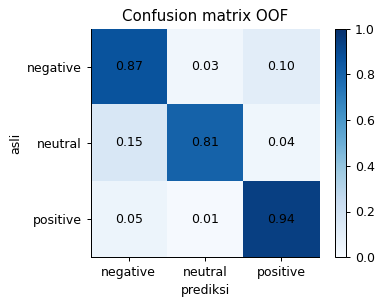

In [15]:
nk.plot_confusion(data, final)

**Contoh salah prediksi** yang paling yakin.

In [16]:
nk.worst_errors(data, final)

,text,label,prediksi,yakin
57,"sudah lama banget pengin ke sini sama pasangan atau teman-teman ramuan sebenarnya , belum lagi dengar-deng...",negative,positive,0.998
197,keluarga besar tubagus chasan bangga pada pasangan jokowi dengan ruf,positive,neutral,0.998
281,"pertama kali nyobain makan di sini , karena review nya sop buntut nya terkenal enak banget . padahal tidak...",negative,positive,0.998
45,"martabak ini sepertinya lebih cocok disebut pancake . rasanya oke , dengan manis yang pas tidak terlalu ma...",negative,positive,0.997
137,tidak pernah bisa bicara kata-kata kasar ke pasangan walau tujuan nya bercanda / memang lagi marah banget ...,positive,negative,0.996
98,"baik beberapa kali ke sini entah buat kerja , perjalanan keluarga , teman-teman atau pasangan . sekadar sa...",negative,positive,0.996
108,lelah nya jadi pak prabowo,neutral,negative,0.996
261,mm sedih deh kalau ke sini selalu menunggu : mie nya pedas banget . hehe bangku nya juga tambahkan dong bi...,negative,positive,0.993


## 11. Keluaran

File `hasil/submission.csv`, `hasil/oof.csv`, `hasil/perbandingan.csv`, dan ringkasan run.

In [17]:
preview = nk.save_outputs(data, final)
nk.finish("semi_supervised", data, board, needs_gpu=bool(MODELS))
preview

tersimpan: hasil/submission.csv (500 baris)
RINGKASAN_RUN task=semi_supervised n_rows=5000 total_detik=2735 gpu=True


,id,label
0,0,negative
1,1,negative
2,2,negative


**Hasil pada data demo SmSA** (500 berlabel, 4.500 tanpa label, batas 60 menit)

- Selesai dalam 46 menit. Model keempat dilewati otomatis karena sisa waktu tidak cukup.
- Test bergeser: AUC adversarial 0,831. Macro-F1 OOF 0,8741 terlalu optimistis dibanding test 0,8156.
- Student terpilih dari skor OOF mirip test, dengan peluang lebih baik 0,99. Test-nya 0,8156, sedangkan teacher 0,8069 dan TF-IDF 0,5322.
- Self-training tidak selalu membantu. Pada uji 200 label, OOF student turun ke 0,6688 dari teacher 0,7714, dan otomatis ditolak.

Saat lomba, ganti catatan ini dengan hasil dari data lomba.